# 1. Exploratory data analysis

Loads the daily station entry and exit tap counts, merges the three Elizabeth line stations that appear under two names, and checks integrity, date coverage, zero-count days, seasonality and the distribution of station size.

## 1.1 Load the raw data

In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, "../src")
import tfl

raw = pd.read_excel("../data/raw/TfL_Station_Counts.xlsx", engine="openpyxl")
raw.head()

,TravelDate,DayOfWeek,Station,EntryTapCount,ExitTapCount
0,20240101,Monday,Abbey Road DLR,395,375
1,20240101,Monday,Abbey Wood,5898,5963
2,20240101,Monday,Acton Central,609,474
3,20240101,Monday,Acton Main Line,1717,1710
4,20240101,Monday,Acton Town,2928,3334


In [2]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 266744 entries, 0 to 266743
Data columns (total 5 columns):
 #   Column         Non-Null Count   Dtype
---  ------         --------------   -----
 0   TravelDate     266744 non-null  int64
 1   DayOfWeek      266744 non-null  str  
 2   Station        266744 non-null  str  
 3   EntryTapCount  266744 non-null  int64
 4   ExitTapCount   266744 non-null  int64
dtypes: int64(3), str(2)
memory usage: 10.2 MB


In [3]:
raw.describe()

,TravelDate,EntryTapCount,ExitTapCount
count,2.667440e+05,266744.000000,266744.000000
mean,2.024471e+07,8965.171235,8937.196882
std,4.843592e+03,13860.434922,14092.088762
min,2.024010e+07,0.000000,0.000000
25%,2.024060e+07,2304.000000,2197.000000
50%,2.024111e+07,4622.000000,4480.000000
75%,2.025041e+07,9097.000000,9018.000000
max,2.025091e+07,141979.000000,142751.000000


## 1.2 Merge renamed stations and parse dates

In [4]:
df = (raw
      .assign(Station=raw["Station"].replace(tfl.RENAME))
      .assign(TravelDate=lambda d: pd.to_datetime(d["TravelDate"].astype(str), format="%Y%m%d"))
      .assign(
          DayNum=lambda d: d["TravelDate"].dt.dayofweek,
          Month=lambda d: d["TravelDate"].dt.month,
          Year=lambda d: d["TravelDate"].dt.year,
          IsWeekend=lambda d: d["DayNum"] >= 5,
      )
)

df.head()

,TravelDate,DayOfWeek,Station,EntryTapCount,ExitTapCount,DayNum,Month,Year,IsWeekend
0,2024-01-01,Monday,Abbey Road DLR,395,375,0,1,2024,False
1,2024-01-01,Monday,Abbey Wood,5898,5963,0,1,2024,False
2,2024-01-01,Monday,Acton Central,609,474,0,1,2024,False
3,2024-01-01,Monday,Acton Main Line,1717,1710,0,1,2024,False
4,2024-01-01,Monday,Acton Town,2928,3334,0,1,2024,False


## 1.3 Integrity checks

In [5]:
# The supplied DayOfWeek string should match the date-derived name on every row.
mismatches = (df["TravelDate"].dt.day_name() != df["DayOfWeek"]).sum()
print("weekday mismatches:", mismatches)

# The merge must not have created two rows for one station on one date.
print("duplicate (station/date):", df.duplicated(["Station", "TravelDate"]).sum())

# 434 stations are expected after the merge.
print("unique stations:", df["Station"].nunique(), "| unique dates:", df["TravelDate"].nunique())

weekday mismatches: 0
duplicate (station/date): 0
unique stations: 434 | unique dates: 622


## 1.4 Date coverage

In [6]:
n_dates = df["TravelDate"].nunique()
coverage = df.groupby("Station").size() / n_dates

print(coverage.describe(), "\n")
coverage.nsmallest(10)

count    434.000000
mean       0.988131
std        0.021203
min        0.670418
25%        0.985531
50%        0.992765
75%        0.996785
max        1.000000
dtype: float64 



Station
Colindale              0.670418
Cutty Sark             0.797428
Wandsworth Road        0.897106
Cyprus                 0.937299
Clapham High Street    0.943730
Tower Gateway          0.943730
Acton Main Line        0.948553
Cockfosters            0.948553
Beckton                0.951768
Oakwood                0.951768
dtype: float64

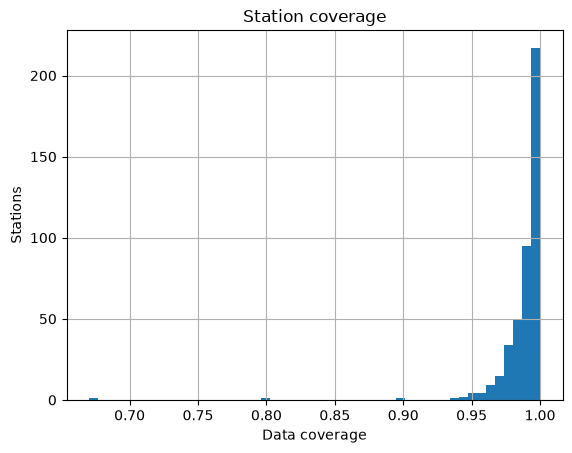

In [7]:
coverage.hist(bins=50)
plt.xlabel("Data coverage"); plt.ylabel("Stations")
plt.title("Station coverage");

## 1.5 Zero-count days

In [8]:
both_zero = (df["EntryTapCount"] == 0) & (df["ExitTapCount"] == 0)
entry_zero = df["EntryTapCount"] == 0
exit_zero = df["ExitTapCount"] == 0

print("both-zero:", both_zero.sum())
print("entry-only zero:", (entry_zero & ~both_zero).sum())
print("exit-only zero:", (exit_zero & ~both_zero).sum())
# No station is fully dark on any day. Partial closures are better found as days far
# below the station's usual level for that weekday, which is done in notebook 4.

both-zero: 0
entry-only zero: 918
exit-only zero: 642


## 1.6 Seasonality

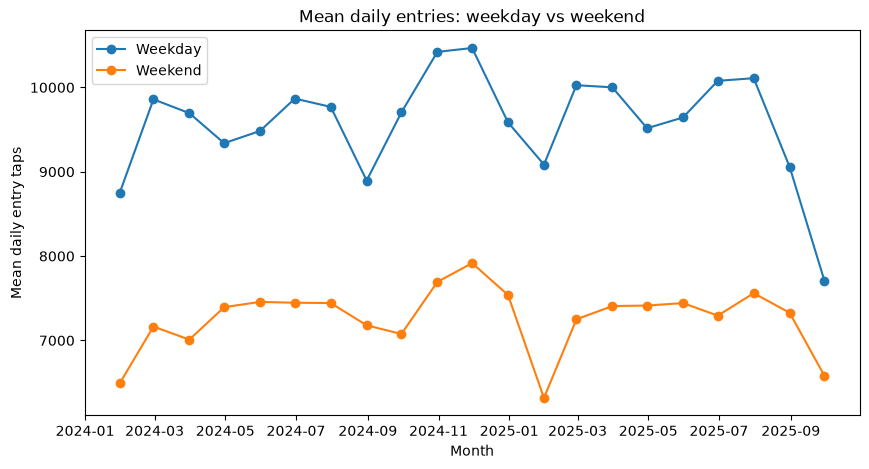

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))

for label, mask in [("Weekday", ~df["IsWeekend"]), ("Weekend", df["IsWeekend"])]:
    monthly = (
        df[mask]
        .set_index("TravelDate")["EntryTapCount"]
        .resample("ME").mean()
    )
    ax.plot(monthly.index, monthly.values, marker="o", label=label)

ax.set_xlabel("Month")
ax.set_ylabel("Mean daily entry taps")
ax.set_title("Mean daily entries: weekday vs weekend")
ax.legend();

## 1.7 Station size

count       434.000000
mean       8924.922562
std       13274.155906
min         196.383855
25%        2446.336842
50%        4745.388716
75%        8746.914388
max      104910.427653
Name: EntryTapCount, dtype: float64 



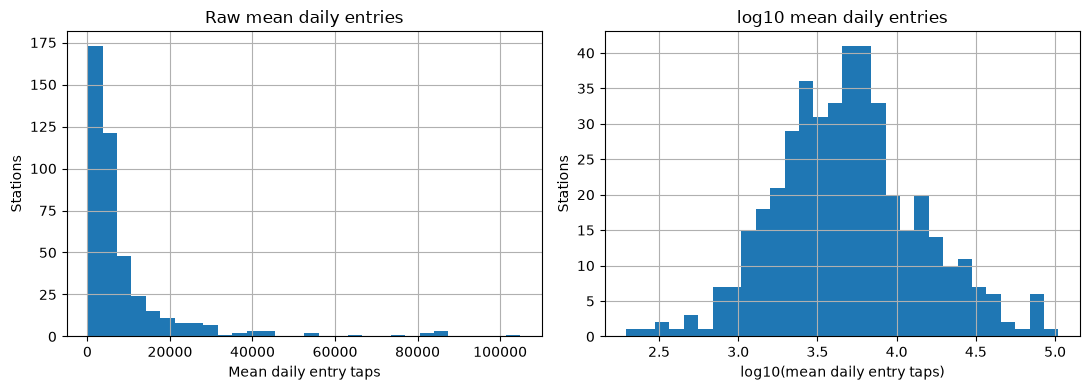

In [10]:
station_size = df.groupby("Station")["EntryTapCount"].mean()
print(station_size.describe(), "\n")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
station_size.hist(bins=30, ax=axes[0])
axes[0].set_title("Raw mean daily entries")
axes[0].set_xlabel("Mean daily entry taps")
axes[0].set_ylabel("Stations")

np.log10(station_size).hist(bins=30, ax=axes[1])
axes[1].set_title("log10 mean daily entries")
axes[1].set_xlabel("log10(mean daily entry taps)")
axes[1].set_ylabel("Stations")

plt.tight_layout()

## 1.8 Save the processed table

In [11]:
import os
os.makedirs("../data/processed", exist_ok=True)
df.to_csv("../data/processed/TfL_Data_Processed.csv", index=False)